# ChurnSense: Exploratory Data Analysis (EDA)

This notebook analyzes the **IBM Telco Customer Churn** dataset (`WA_Fn-UseC_-Telco-Customer-Churn.csv`).
We inspect data types, identify missing/whitespace values, explore feature distributions, and evaluate churn correlations.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style='whitegrid')
palette = {'No': '#3b82f6', 'Yes': '#ef4444'}

df = pd.read_csv('../data/raw/WA_Fn-UseC_-Telco-Customer-Churn.csv')
print(f'Dataset Shape: {df.shape}')
df.head()

In [2]:
# Inspect data types and standard null values
print('Data types:')
print(df.dtypes)
print('\nNull count per column:')
print(df.isnull().sum())

Data types:
customerID                str
gender                    str
SeniorCitizen           int64
Partner                   str
Dependents                str
tenure                  int64
PhoneService              str
MultipleLines             str
InternetService           str
OnlineSecurity            str
OnlineBackup              str
DeviceProtection          str
TechSupport               str
StreamingTV               str
StreamingMovies           str
Contract                  str
PaperlessBilling          str
PaymentMethod             str
MonthlyCharges        float64
TotalCharges              str
Churn                     str
TotalCharges_Clean    float64
Churn_Binary            int64

Null count per column:
customerID            0
gender                0
SeniorCitizen         0
Partner               0
Dependents            0
tenure                0
PhoneService          0
MultipleLines         0
InternetService       0
OnlineSecurity        0
OnlineBackup          0
DeviceProt

In [3]:
# Inspect TotalCharges whitespace issue
spaces_count = (df['TotalCharges'] == ' ').sum()
tenure_at_space = df[df['TotalCharges'] == ' ']['tenure'].unique()
print(f'Blank spaces found in TotalCharges: {spaces_count}')
print(f'Corresponding tenure values for blank TotalCharges: {tenure_at_space}')

# Fix TotalCharges: convert to numeric and fill newly created NaNs with 0.0
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'].str.strip(), errors='coerce').fillna(0.0)
df['Churn_Binary'] = (df['Churn'] == 'Yes').astype(int)
print('Converted TotalCharges to numeric, filled 11 nulls with 0.0.')

Blank spaces found in TotalCharges: 11
Corresponding tenure values for blank TotalCharges: [0]
Converted TotalCharges to numeric, filled 11 nulls with 0.0.


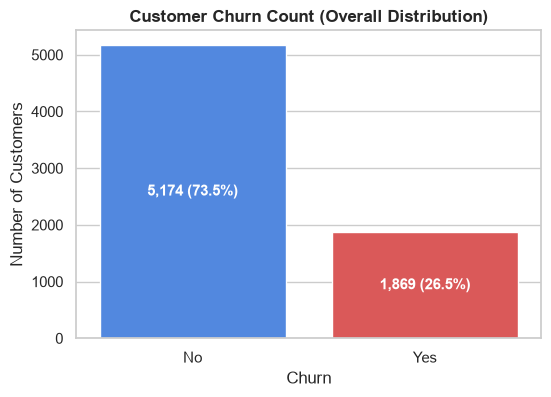

In [4]:
# Churn target distribution
fig, ax = plt.subplots(figsize=(6, 4))
sns.countplot(data=df, x='Churn', palette=palette, ax=ax)
ax.set_title('Customer Churn Count (Overall Distribution)', fontsize=12, fontweight='bold')
ax.set_ylabel('Number of Customers')
for p in ax.patches:
    height = p.get_height()
    ax.annotate(f'{height:,.0f} ({height/len(df)*100:.1f}%)',
                (p.get_x() + p.get_width() / 2., height / 2),
                ha='center', va='center', color='white', fontweight='bold', fontsize=11)
plt.show()

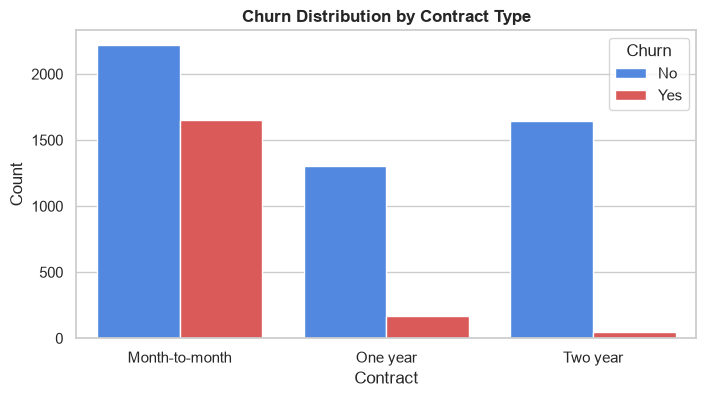

In [5]:
# Churn vs Contract Type
fig, ax = plt.subplots(figsize=(8, 4))
sns.countplot(data=df, x='Contract', hue='Churn', palette=palette, ax=ax)
ax.set_title('Churn Distribution by Contract Type', fontsize=12, fontweight='bold')
ax.set_ylabel('Count')
plt.show()

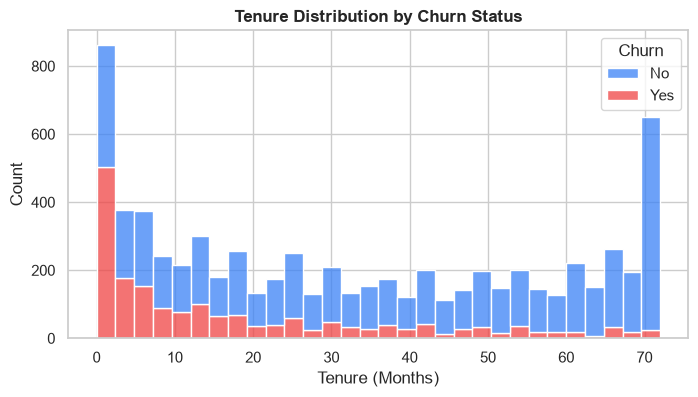

In [6]:
# Churn vs Tenure Histogram
fig, ax = plt.subplots(figsize=(8, 4))
sns.histplot(data=df, x='tenure', hue='Churn', multiple='stack', palette=palette, bins=30, ax=ax)
ax.set_title('Tenure Distribution by Churn Status', fontsize=12, fontweight='bold')
ax.set_xlabel('Tenure (Months)')
plt.show()

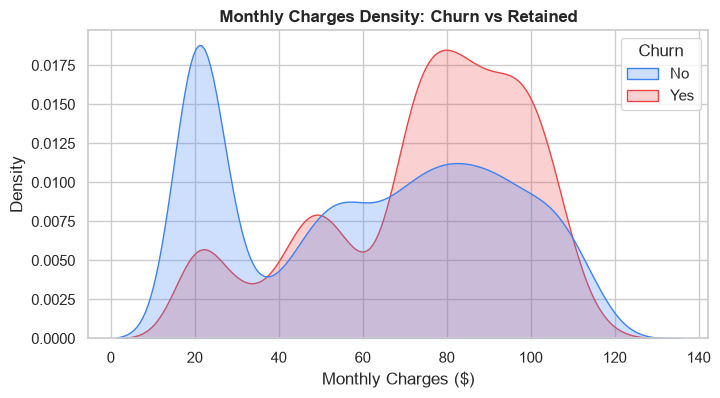

In [7]:
# Churn vs Monthly Charges Density
fig, ax = plt.subplots(figsize=(8, 4))
sns.kdeplot(data=df, x='MonthlyCharges', hue='Churn', common_norm=False, palette=palette, fill=True, ax=ax)
ax.set_title('Monthly Charges Density: Churn vs Retained', fontsize=12, fontweight='bold')
ax.set_xlabel('Monthly Charges ($)')
plt.show()

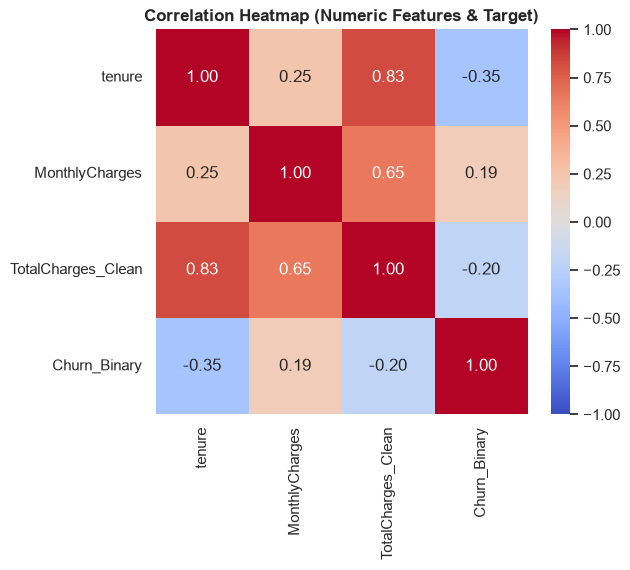

In [8]:
# Correlation Heatmap of Numeric Features
fig, ax = plt.subplots(figsize=(6, 5))
corr = df[['tenure', 'MonthlyCharges', 'TotalCharges', 'Churn_Binary']].corr()
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt='.2f', vmin=-1, vmax=1, ax=ax)
ax.set_title('Correlation Heatmap (Numeric Features & Target)', fontsize=12, fontweight='bold')
plt.show()

## Key Findings & EDA Insights

1. **Imbalanced Target Class (~26.5% Churn):** 1,869 customers churned (26.5%) vs 5,174 retained (73.5%). The evaluation strategy must focus on ROC-AUC, F1-score, and recall rather than raw accuracy, with class weighting (`scale_pos_weight` / `class_weight='balanced'`).
2. **Contract Structure is Paramount:** Month-to-month contracts experience drastically higher churn rates (>42%) compared to one-year (~11%) and two-year (~3%) agreements. Long-term contracts serve as an effective retention anchor.
3. **Critical High-Risk Tenure Window:** Peak churn occurs in the first 0 to 12 months. Once a customer remains beyond 24-36 months, the probability of churn drops precipitously.
4. **High Monthly Charges Accelerate Attrition:** Churn density peaks between $70 and $105/month, primarily associated with Fiber optic internet users without bundled security or tech support.
5. **Data Quality Issue in TotalCharges:** Exactly 11 records have whitespace (`' '`) in `TotalCharges`, all with `tenure == 0`. Converting these strings to float and imputing `0.0` reflects newly enrolled customers without dropping data.